In [1]:
import os
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt

def load_tiff_frame(path, index):
    """Load one frame (page) from a multi-page TIFF without reading the rest."""
    with tifffile.TiffFile(path) as tif:
        n = len(tif.pages)
        if not -n <= index < n:
            raise IndexError(f"Frame {index} out of range (file has {n} frames)")
        return tif.pages[index].asarray(),n

In [25]:
data, n = load_tiff_frame("/Users/ashleycadby/Downloads/control_MMStack_Pos0.ome.tif", 0)

In [7]:
data = data-np.mean(data)
data_line = np.reshape(data, (data.shape[0]*data.shape[1]))

(-50.0, 150.0, 0.0, 100000.0)

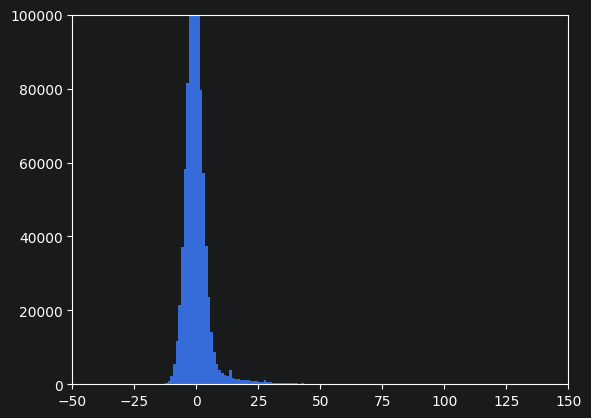

In [21]:
plt.hist(data_line,bins=10000)
plt.axis([-50,150,0,100000])

In [4]:
data, n = load_tiff_frame("/Users/ashleycadby/Downloads/control_MMStack_Pos0.ome.tif",0)
holdall_dark = []
holdall_real = []

for I in range(0,n,5):
    data, n = load_tiff_frame("/Users/ashleycadby/Downloads/control_MMStack_Pos0.ome.tif",I)
    holdall_dark.append(data-np.mean(data))
    holdall_real.append(data)
noise_data = np.array(holdall_dark)
real = np.array(holdall_real)


(-50.0, 150.0, 0.0, 10000000.0)

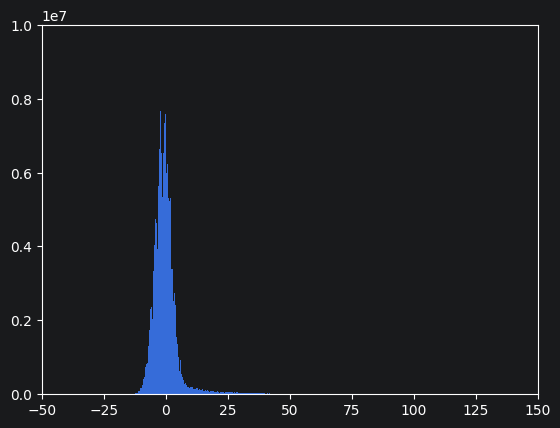

In [5]:
threshold = 200
X = np.reshape(noise_data, (noise_data.shape[0]*noise_data.shape[1]*noise_data.shape[2]))
mask = X < threshold        # [[ True, False,  True], [False,  True,  True]]
below = X[mask]             # array([ 3,  7,
plt.hist(below,bins=1000)
plt.axis([-50,150,0,10000000])

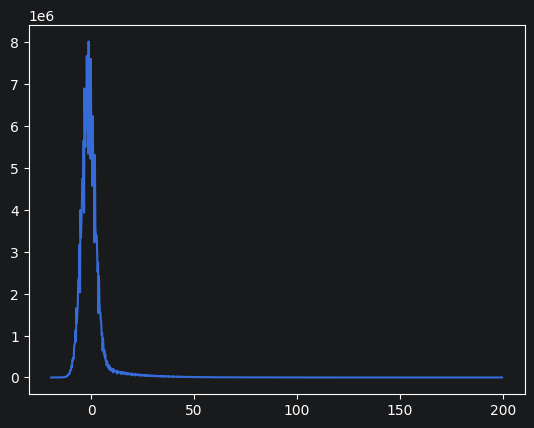

In [6]:
hist, bin_edges = np.histogram(below, bins=1000)
plt.plot(bin_edges[:-1], hist)

In [7]:
from scipy.optimize import curve_fit
def build_gaussian(x_data, offset, xo, sigma, amplitude):
    y_val = offset + amplitude * np.exp((-1 * (xo-x_data)**2)/sigma**2)
    return(y_val)


In [ ]:
guess = [np.min(hist), 0, 4, np.max(hist)]

# Then I give the curve fit command the fitting function I want, the data and my guesses
popt, pcov = curve_fit(build_gaussian, hist, bin_edges[:-1], p0=np.asarray(guess))

print(popt)
fitted_data = build_gaussian(bin_edges[:-1], popt[0], popt[1], popt[2], popt[3])

plt.plot(bin_edges[:-1], fitted_data)
plt.show()

(-20.0, 20.0, 0.0, 8000000.0)

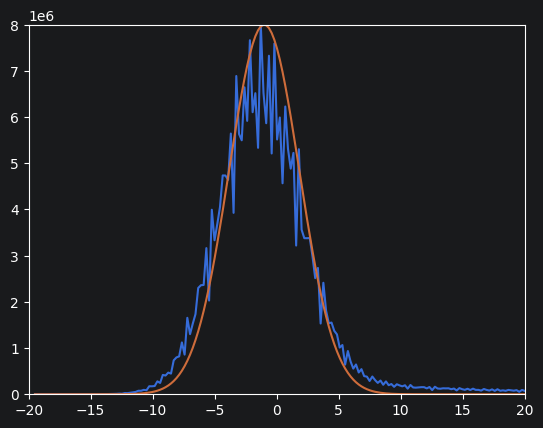

In [8]:
hist, bin_edges = np.histogram(below, bins=1000)
plt.plot(bin_edges[:-1], hist)
fitted_data = build_gaussian(bin_edges[:-1], 0 ,-1, 4, 8000000)
plt.plot(bin_edges[:-1], fitted_data)
plt.axis([-20,20, 0,8000000])


(450.0, 550.0, 0.0, 40000000.0)

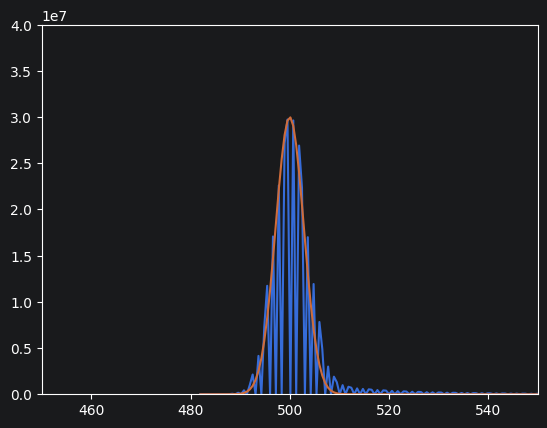

In [30]:
threshold = 600
real_line = np.reshape(real, (real.shape[0]*real.shape[1]*real.shape[2]))
mask = real_line < threshold
new_real = real_line[mask]
hist, bin_edges = np.histogram(new_real, bins=200)
plt.plot(bin_edges[:-1], hist)
fitted_data = build_gaussian(bin_edges[:-1], 0 ,500, 4, 30000000)
plt.plot(bin_edges[:-1], fitted_data)
plt.axis([450,550, 0,40000000])